# Subperfiles anidados (arbol de arriba hacia abajo)

El arbol del notebook 07, construido de abajo hacia arriba, resulto inestable (ARI 0.33): sobre
un continuo, los cortes cambian con cada remuestreo. Aqui se invierte la direccion:

1. **Perfiles:** las 6 clases latentes del notebook 08 (ARI bootstrap 0.99), que combinan nivel
   y forma de la trayectoria. Alternativa: los 4 perfiles del notebook 04 (ARI 0.74).
2. **Subperfiles:** KMeans ponderado dentro de cada perfil. El numero de subperfiles de cada
   perfil es el mayor que resulta estable en bootstrap.

Para microtargeting, cada subperfil se describe con las entidades, personas-tipo (sexo x edad) y
municipios donde esta sobrerrepresentado.

## 1. Configuracion

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 120, "figure.facecolor": "white"})

## 2. Parametros y rutas

- `ORIGEN_PERFILES`: `"clases_latentes"` (notebook 08) o `"base_04"` (notebook 04).
- `SUB_VARIABLES`: espacio en que se subdivide cada perfil (promedio, brecha y tendencia).
- `K_SUB_FIJO`: fija a mano el numero de subperfiles por perfil.

In [2]:
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DIR_PREPROCESSED = ROOT / "DATA" / "PREPROCESSED"

ELECCIONES = ["P2009", "P2012", "P2015", "P2018", "P2021", "P2024"]
CORTES_EDAD = [17, 24, 29, 39, 49, 59, 69, 79, 200]
ETIQUETAS_EDAD = ["18-24", "25-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"]
LLAVES = ["EDOCVE", "SECCION", "SEXO", "GRUPO_EDAD"]
BASE = ["promedio", "brecha_pres", "tendencia"]

ORIGEN_PERFILES = "clases_latentes"
SUB_VARIABLES = BASE
K_SUB_RANGO = range(2, 6)
K_SUB_FIJO = None  # ej. {0: 3, 1: 2, 2: 3, 3: 3}
MIN_PCT_SUB = 2.0  # % de la poblacion total
ARI_ESTABLE = 0.8

N_EVAL = 10_000
N_SIL = 5_000
N_BOOT = 3
MIN_PERSONAS_ENTIDAD = 20_000
MIN_PERSONAS_TIPO = 20_000
MIN_PERSONAS_MPIO = 1_000
RANDOM_STATE = 42

COLORES_PERFIL = ["#3288bd", "#66c2a5", "#fee08b", "#fdae61", "#f46d43", "#d53e4f",
                  "#9e0142", "#5e4fa2"]
EDONOM = {
    1: "Aguascalientes", 2: "Baja California", 3: "Baja California Sur",
    4: "Campeche", 5: "Coahuila", 6: "Colima", 7: "Chiapas", 8: "Chihuahua",
    9: "Ciudad de Mexico", 10: "Durango", 11: "Guanajuato", 12: "Guerrero",
    13: "Hidalgo", 14: "Jalisco", 15: "Mexico", 16: "Michoacan", 17: "Morelos",
    18: "Nayarit", 19: "Nuevo Leon", 20: "Oaxaca", 21: "Puebla", 22: "Queretaro",
    23: "Quintana Roo", 24: "San Luis Potosi", 25: "Sinaloa", 26: "Sonora",
    27: "Tabasco", 28: "Tamaulipas", 29: "Tlaxcala", 30: "Veracruz",
    31: "Yucatan", 32: "Zacatecas",
}

### 2.1 Funciones auxiliares

Resumenes ponderados por peso y R2 ponderado (proporcion de varianza explicada por los grupos).

In [3]:
def media_ponderada(df, col, por):
    grupos = [df[c] for c in por]
    wx = (df[col] * df["peso"]).groupby(grupos).sum()
    return wx / df["peso"].where(df[col].notna()).groupby(grupos).sum()


def dominante(df, por, col):
    t = df.groupby(por + [col])["peso"].sum()
    return t.groupby(level=por).idxmax().map(lambda x: x[-1])


def r2_ponderado(Z, labels, w):
    wl = np.bincount(labels, weights=w)
    centros = np.stack([np.bincount(labels, weights=w * Z[:, j]) for j in range(Z.shape[1])], axis=1)
    centros = centros / wl[:, None]
    total = (w[:, None] * (Z - np.average(Z, axis=0, weights=w)) ** 2).sum()
    dentro = (w[:, None] * (Z - centros[labels]) ** 2).sum()
    return 1 - dentro / total


def resumen(df, por):
    personas = df.groupby(por)["peso"].sum()
    out = pd.DataFrame({"personas": personas, "pct_pob": personas / df["peso"].sum() * 100})
    for col in ["promedio", "brecha_pres", "tendencia", "desviacion", "P_PJ2025", "MUJER", "RURAL_MIXTA"]:
        out[col] = media_ponderada(df, col, por)
    out[["MUJER", "RURAL_MIXTA"]] *= 100
    out["edad_dominante"] = dominante(df, por, "GRUPO_EDAD")
    out["region_dominante"] = dominante(df, por, "REGION")
    return out.round(1)

## 3. Carga de datos

### 3.1 Celdas, peso, PJ 2025 y municipio

Celdas del notebook 03 con peso = SV + NV de 2024. Se conservan las celdas sin tasa PJ 2025
(Campeche no tiene datos de la eleccion judicial); los promedios PJ usan solo celdas con dato.

In [4]:
celdas = pd.read_parquet(DIR_PREPROCESSED / "celdas_historial.parquet")
celdas["GRUPO_EDAD"] = celdas["GRUPO_EDAD"].astype(str)

fed24 = pd.read_parquet(
    DIR_PREPROCESSED / "conteos_federal_2009_2024.parquet",
    columns=["EDOCVE", "SECCION", "SEXO", "EDAD", "AELEC", "SV", "NV", "MPIOCVE", "MPIONOM"],
    filters=[("AELEC", "==", 2024)],
)
fed24["GRUPO_EDAD"] = pd.cut(fed24["EDAD"], bins=CORTES_EDAD, labels=ETIQUETAS_EDAD)
fed24["VOTANTES"] = fed24["SV"] + fed24["NV"]
pesos = (
    fed24.groupby(LLAVES, observed=True)["VOTANTES"]
    .sum()
    .reset_index()
    .rename(columns={"VOTANTES": "peso"})
)
pesos["GRUPO_EDAD"] = pesos["GRUPO_EDAD"].astype(str)
sec_mpio = (
    fed24.groupby(["EDOCVE", "SECCION"])
    .agg(MPIOCVE=("MPIOCVE", "first"), MPIONOM=("MPIONOM", "first"))
    .reset_index()
)
del fed24

secciones = pd.read_parquet(
    DIR_PREPROCESSED / "secciones_historial.parquet", columns=["EDOCVE", "SECCION", "P_PJ2025"]
)
celdas = (
    celdas.merge(pesos, on=LLAVES, how="left")
    .merge(secciones, on=["EDOCVE", "SECCION"], how="left")
    .merge(sec_mpio, on=["EDOCVE", "SECCION"], how="left")
    .dropna(subset=["peso"])
    .reset_index(drop=True)
)
del pesos, secciones, sec_mpio

celdas["MUJER"] = (celdas["SEXO"] == 1).astype(float)
celdas["RURAL_MIXTA"] = (celdas["TIPOSEC"].astype(str) != "U").astype(float)
celdas["persona_tipo"] = celdas["SEXO"].map({0: "Hombre", 1: "Mujer"}) + " " + celdas["GRUPO_EDAD"]
w = celdas["peso"].to_numpy(dtype=float)
idx_eval = np.random.default_rng(RANDOM_STATE).choice(len(celdas), size=N_EVAL, replace=False, p=w / w.sum())
print(f"Celdas: {len(celdas):,}  peso: {w.sum():,.0f}")

Celdas: 657,497  peso: 71,203,577


### 3.2 Perfiles

- `clases_latentes`: columna `clase` de `celdas_clases_latentes.parquet` (notebook 08).
- `base_04`: columna `base_04` de `celdas_perfiles_candidatos.parquet` (reajuste del modelo del
  notebook 04 en el notebook 05).

En ambos casos se renumeran por promedio de participacion (0 = menor).

In [5]:
ORIGENES = {
    "clases_latentes": ("celdas_clases_latentes.parquet", "clase"),
    "base_04": ("celdas_perfiles_candidatos.parquet", "base_04"),
}
archivo, columna = ORIGENES[ORIGEN_PERFILES]
origen = pd.read_parquet(DIR_PREPROCESSED / archivo, columns=LLAVES + [columna])
n0 = len(celdas)
celdas = celdas.merge(origen.rename(columns={columna: "perfil_origen"}), on=LLAVES, how="inner")
print(f"Celdas sin perfil de origen (excluidas): {n0 - len(celdas):,}")
w = celdas["peso"].to_numpy(dtype=float)
idx_eval = np.random.default_rng(RANDOM_STATE).choice(len(celdas), size=N_EVAL, replace=False, p=w / w.sum())

orden = media_ponderada(celdas, "promedio", ["perfil_origen"]).sort_values().index
celdas["perfil"] = celdas["perfil_origen"].map({old: new for new, old in enumerate(orden)}).astype(int)
celdas = celdas.drop(columns="perfil_origen")
K_PERFILES = celdas["perfil"].nunique()
print(f"Perfiles: {ORIGEN_PERFILES} ({K_PERFILES})")
resumen(celdas, ["perfil"])

Celdas sin perfil de origen (excluidas): 0
Perfiles: clases_latentes (6)


,personas,pct_pob,promedio,brecha_pres,tendencia,desviacion,P_PJ2025,MUJER,RURAL_MIXTA,edad_dominante,region_dominante
perfil,,,,,,,,,,,
0,15253119,21.4,37.3,14.3,1.1,10.5,11.1,25.4,26.7,30-39,Centro
1,5934456,8.3,48.5,7.6,-1.6,8.9,10.0,43.5,36.2,30-39,Occidente
2,13265429,18.6,50.5,18.4,3.0,13.5,14.0,52.6,23.7,30-39,Centro
3,11639641,16.3,60.3,9.3,-0.1,8.7,11.9,56.7,32.5,40-49,Centro
4,8413205,11.8,62.0,19.5,4.5,14.9,15.2,68.2,27.3,40-49,Centro
5,16697727,23.5,72.8,10.6,1.8,9.3,15.0,68.9,37.6,50-59,Centro


### 3.3 Espacio de clustering

Estandarizacion ponderada por peso. `Z_base` reproduce el espacio de los perfiles y `Z` es el
espacio de subdivision (iguales con la configuracion por defecto).

In [6]:
def estandarizar(cols):
    X = celdas[cols].to_numpy(dtype=float)
    return StandardScaler().fit(X, sample_weight=w).transform(X)


Z_base = estandarizar(BASE)
Z = estandarizar(SUB_VARIABLES)
perfil = celdas["perfil"].to_numpy()
print(f"Espacio de subdivision: {SUB_VARIABLES}")

Espacio de subdivision: ['promedio', 'brecha_pres', 'tendencia']


## 4. Estabilidad de los perfiles

Si los perfiles no fueran estables, no tendria sentido anidar subperfiles en ellos. Las clases
latentes ya se evaluaron en el notebook 08 (bootstrap de Poisson, ARI 0.99). Para `base_04` se
repite aqui el bootstrap de Poisson (peso x Poisson(1)) del KMeans de 4 perfiles.

In [7]:
if ORIGEN_PERFILES == "base_04":
    aris = []
    for b in range(N_BOOT):
        w_b = w * np.random.default_rng(1000 + b).poisson(1.0, size=len(w))
        lab_b = KMeans(K_PERFILES, n_init=5, random_state=1000 + b).fit(Z_base, sample_weight=w_b).labels_
        aris.append(adjusted_rand_score(perfil[idx_eval], lab_b[idx_eval]))
    print(f"ARI de perfiles: medio {np.mean(aris):.3f}, minimo {np.min(aris):.3f}")
else:
    print("Estabilidad de las clases latentes: ver notebook 08 (seccion 7.1).")

Estabilidad de las clases latentes: ver notebook 08 (seccion 7.1).


## 5. Subperfiles

### 5.1 Numero de subperfiles por perfil

Para cada perfil y k = 2-5: KMeans ponderado sobre las celdas del perfil, silhouette sobre una
muestra ponderada de 5k celdas del perfil, R2 dentro del perfil, tamano del subperfil mas chico
(% de la poblacion total) y ARI medio en 3 bootstraps.

In [8]:
def muestra_perfil(mask, seed):
    idx = np.flatnonzero(mask)
    return np.random.default_rng(seed).choice(
        idx, size=min(N_SIL, len(idx)), replace=False, p=w[idx] / w[idx].sum()
    )


filas, modelos_sub = [], {}
for p in range(K_PERFILES):
    mask = perfil == p
    idx_s = muestra_perfil(mask, RANDOM_STATE + p)
    for k in K_SUB_RANGO:
        km = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(Z[mask], sample_weight=w[mask])
        modelos_sub[(p, k)] = km
        lab_s = km.predict(Z[idx_s])
        aris = []
        for b in range(N_BOOT):
            w_b = w[mask] * np.random.default_rng(1000 + b).poisson(1.0, size=mask.sum())
            km_b = KMeans(k, n_init=3, random_state=1000 + b).fit(Z[mask], sample_weight=w_b)
            aris.append(adjusted_rand_score(lab_s, km_b.predict(Z[idx_s])))
        tam = np.bincount(km.labels_, weights=w[mask], minlength=k) / w.sum() * 100
        filas.append({
            "perfil": p, "k": k,
            "silhouette": silhouette_score(Z[idx_s], lab_s),
            "r2": r2_ponderado(Z[mask], km.labels_, w[mask]),
            "pct_min_total": tam.min(),
            "ari_boot": np.mean(aris),
        })

seleccion = pd.DataFrame(filas)
seleccion.round(3)

,perfil,k,silhouette,r2,pct_min_total,ari_boot
0,0,2,0.349,0.408,9.581,0.974
1,0,3,0.263,0.523,5.099,0.966
2,0,4,0.269,0.606,4.210,0.951
3,0,5,0.257,0.649,3.307,0.956
4,1,2,0.345,0.392,3.541,0.981
5,1,3,0.308,0.538,2.328,0.981
6,1,4,0.285,0.622,1.562,0.962
7,1,5,0.277,0.676,0.935,0.912
8,2,2,0.335,0.386,8.620,0.990
9,2,3,0.319,0.534,4.478,0.948


### 5.2 Eleccion

Por perfil, el mayor k que es estable (ARI >= 0.8) y cuyo subperfil mas chico tiene al menos 2%
de la poblacion: el mayor detalle que sigue siendo reproducible. Si ningun k cumple, el de mayor
silhouette.

In [9]:
if K_SUB_FIJO is None:
    K_SUB = {}
    for p, d in seleccion.groupby("perfil"):
        ok = d[(d["ari_boot"] >= ARI_ESTABLE) & (d["pct_min_total"] >= MIN_PCT_SUB)]
        K_SUB[p] = int(ok["k"].max()) if len(ok) else int(d.loc[d["silhouette"].idxmax(), "k"])
else:
    K_SUB = K_SUB_FIJO
print(f"Subperfiles por perfil: {K_SUB}  (total {sum(K_SUB.values())})")

Subperfiles por perfil: {0: 5, 1: 3, 2: 5, 3: 5, 4: 4, 5: 5}  (total 27)


### 5.3 Asignacion

Los subperfiles se numeran dentro de su perfil por promedio de participacion (ej. 2.1, 2.2).

In [10]:
sub_k = np.full(len(celdas), -1)
for p, k in K_SUB.items():
    sub_k[perfil == p] = modelos_sub[(p, k)].labels_
celdas["sub_k"] = sub_k

prom = (
    media_ponderada(celdas, "promedio", ["perfil", "sub_k"])
    .rename("prom")
    .reset_index()
    .sort_values("prom")
)
prom["subperfil"] = prom["perfil"].astype(str) + "." + (prom.groupby("perfil").cumcount() + 1).astype(str)
celdas = celdas.merge(prom[["perfil", "sub_k", "subperfil"]], on=["perfil", "sub_k"], how="left")

estab = seleccion.set_index(["perfil", "k"]).loc[list(K_SUB.items()), ["silhouette", "ari_boot"]]
estab.round(3)

,,silhouette,ari_boot
perfil,k,,
0,5,0.257,0.956
1,3,0.308,0.981
2,5,0.288,0.944
3,5,0.278,0.931
4,4,0.284,0.973
5,5,0.261,0.951


## 6. Caracterizacion

### 6.1 Resumen por subperfil

In [11]:
tabla_sub = resumen(celdas, ["perfil", "subperfil"])
tabla_sub

personas  pct_pob  promedio  brecha_pres  tendencia  \
perfil subperfil                                                        
0      0.1         2356390      3.3      33.2          6.1       -2.0   
       0.2         2777656      3.9      37.3         14.8        3.3   
       0.3         4586956      6.4      37.7         15.6        0.2   
       0.4         3177680      4.5      38.7         23.2        2.6   
       0.5         2354437      3.3      38.9          7.2        1.3   
1      1.1         1657911      2.3      47.6          2.2       -3.8   
       1.2         2461403      3.5      48.7         13.4       -1.2   
       1.3         1815142      2.5      49.2          4.5       -0.3   
2      2.1         1650623      2.3      49.1         22.2        6.4   
       2.2         3545641      5.0      49.5         26.6        3.2   
       2.3         3403187      4.8      50.6         18.5        1.0   
       2.4         2749250      3.9      51.1         13.5        4.3   
       2.5         1916728      2.7      52.3          7.0        1.2   
3      3.1         2584664      3.6      58.4         17.4        1.2   
       3.2         2823201      4.0      59.8         11.0       -1.3   
       3.3         2426802      3.4      60.2         10.1        1.8   
       3.4         2221206      3.1      61.7          2.9       -0.2   
       3.5         1583768      2.2      62.2          0.7       -3.1   
4      4.1         2096002      2.9      60.7         26.6        3.8   
       4.2         2760920      3.9      61.6         18.2        2.9   
       4.3         1897720      2.7      62.7         21.9        7.3   
       4.4         1658563      2.3      63.7         10.0        4.9   
5      5.1         3846091      5.4      69.4         17.3        2.3   
       5.2         3512479      4.9      70.4         10.1        0.1   
       5.3         2297323      3.2      73.1         17.1        5.3   
       5.4         3855088      5.4      75.4          7.9        2.7   
       5.5         3186746      4.5      76.5          1.8       -0.6   

                  desviacion  P_PJ2025  MUJER  RURAL_MIXTA edad_dominante  \
perfil subperfil                                                            
0      0.1               8.2       8.9   16.7         47.6          18-24   
       0.2              11.1      12.4   26.9         24.2          30-39   
       0.3              10.2      10.4   26.5         20.9          30-39   
       0.4              14.0      12.1   29.4         11.8          30-39   
       0.5               8.0      11.7   24.6         40.5          18-24   
1      1.1               9.9       9.2   38.4         51.7          30-39   
       1.2              10.2      10.0   50.5         27.3          30-39   
       1.3               6.2      10.6   38.6         34.2          30-39   
2      2.1              17.3      14.9   50.4         25.0          18-24   
       2.2              15.9      14.1   58.9          9.5          30-39   
       2.3              12.0      13.0   55.0         18.9          30-39   
       2.4              12.7      14.7   49.9         32.6          30-39   
       2.5               9.5      13.6   42.3         44.9          30-39   
3      3.1              11.0      13.2   60.2         17.0          40-49   
       3.2               9.1      11.1   60.9         31.1          40-49   
       3.3               8.4      13.2   54.4         27.4          50-59   
       3.4               6.1      11.3   53.7         40.2          50-59   
       3.5               8.7      10.2   51.7         57.3          40-49   
4      4.1              16.2      14.4   77.7         11.8          40-49   
       4.2              12.5      15.0   62.2         21.0          40-49   
       4.3              18.5      15.8   70.8         36.8          40-49   
       4.4              13.1      15.8   63.1         46.7          30-39   
5      5.1              11.1      15.0   71.8       

### 6.2 Trayectorias

Un panel por perfil con la trayectoria ponderada de cada subperfil.

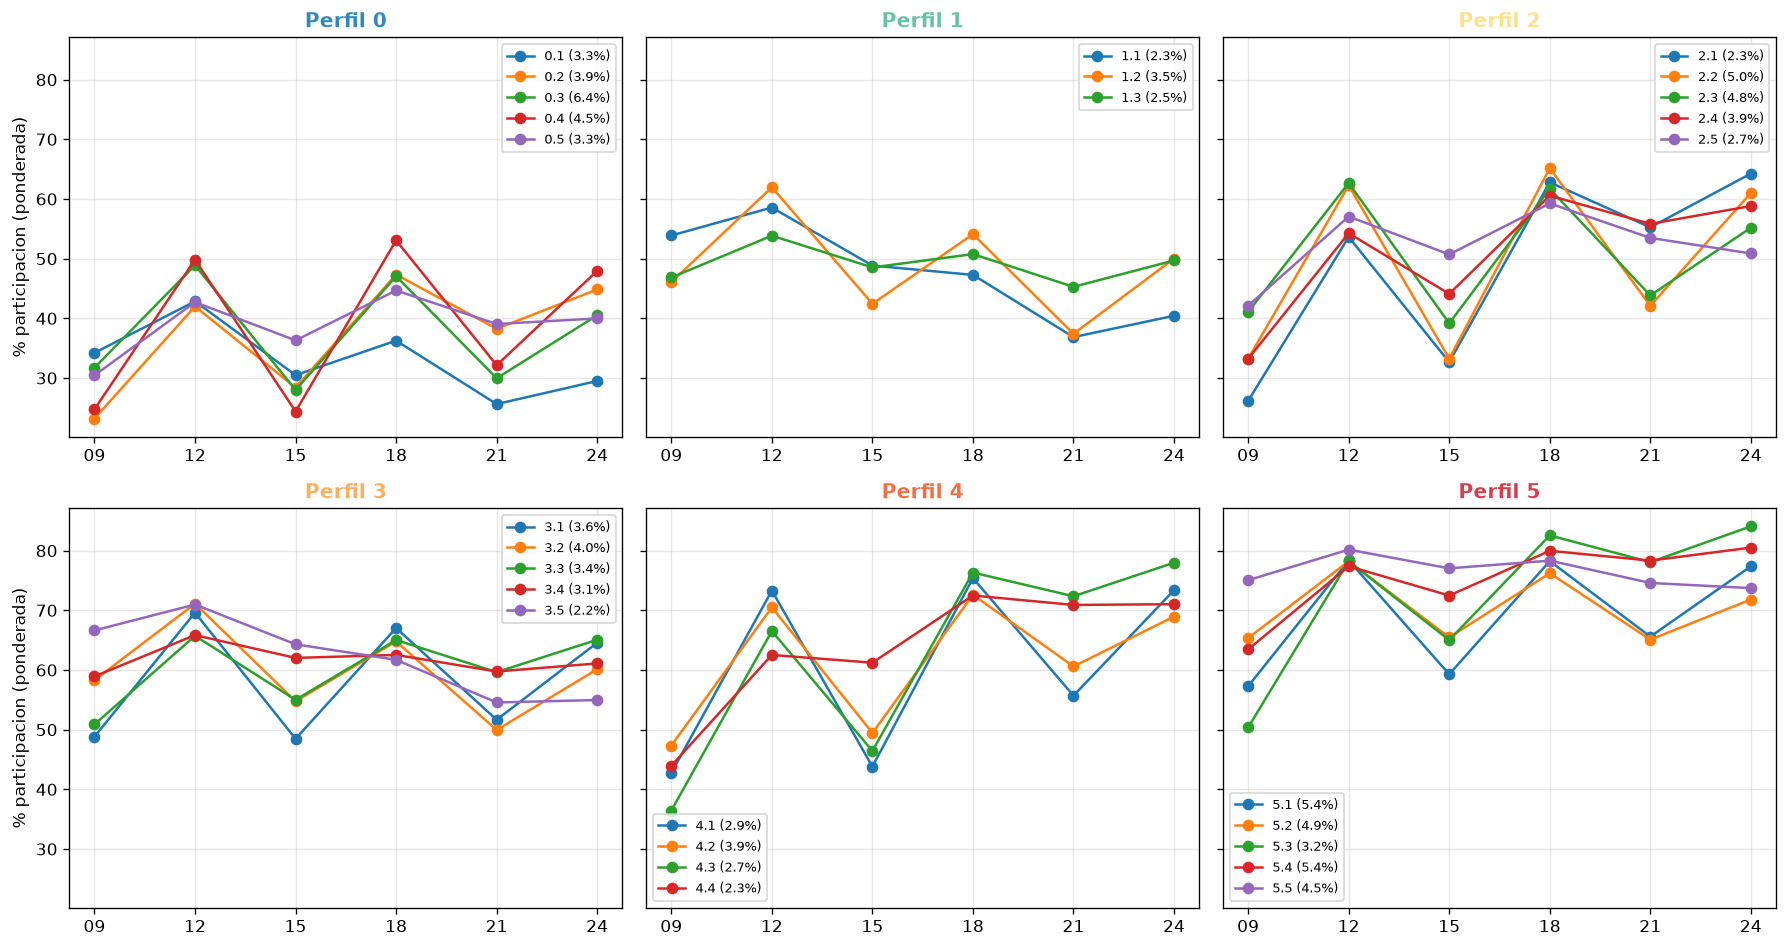

In [12]:
anos = [2009, 2012, 2015, 2018, 2021, 2024]
tray = pd.DataFrame({e: media_ponderada(celdas, e, ["perfil", "subperfil"]) for e in ELECCIONES})

ncols = min(K_PERFILES, 3)
nrows = int(np.ceil(K_PERFILES / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows), sharey=True, squeeze=False)
axes = axes.ravel()
for ax in axes[K_PERFILES:]:
    ax.set_visible(False)
for p, ax in enumerate(axes[:K_PERFILES]):
    for (pp, s), fila in tray.loc[[p]].iterrows():
        ax.plot(anos, fila.to_numpy(), "o-", label=f"{s} ({tabla_sub.loc[(pp, s), 'pct_pob']:.1f}%)")
    ax.set_title(f"Perfil {p}", color=COLORES_PERFIL[p], fontweight="bold")
    ax.set_xticks(anos, [str(a)[2:] for a in anos])
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
for ax in axes[::ncols]:
    ax.set_ylabel("% participacion (ponderada)")
plt.tight_layout()
plt.show()

### 6.3 Mapa de subperfiles

Cada burbuja es un subperfil, con tamano proporcional a las personas que representa.

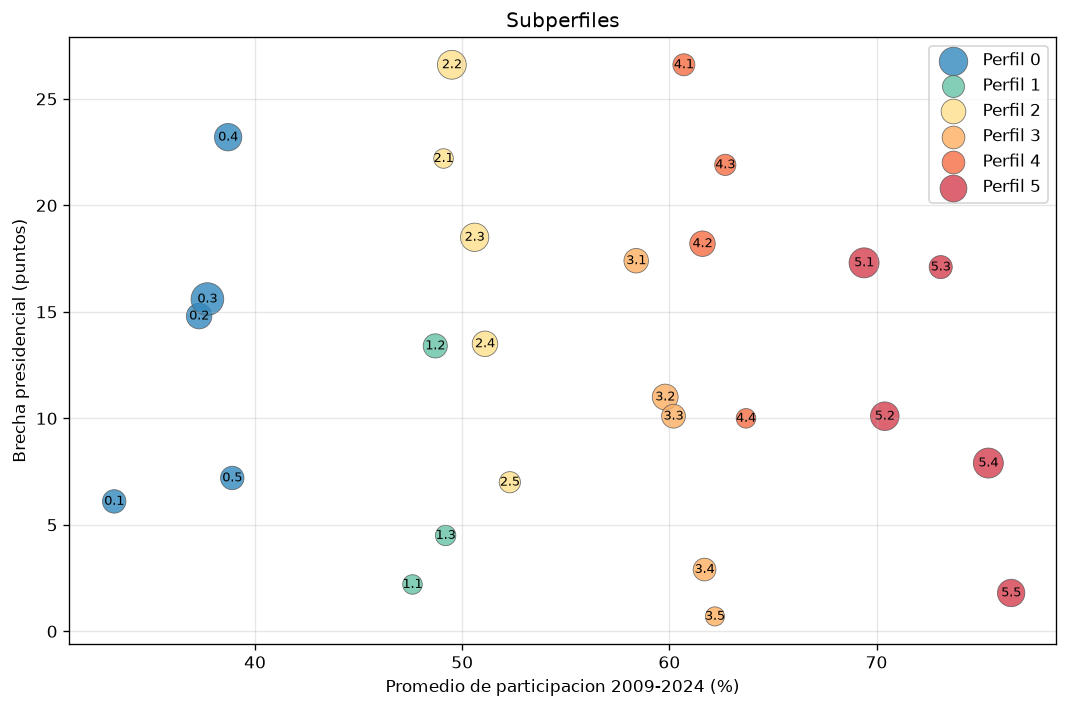

In [13]:
t = tabla_sub.reset_index()

fig, ax = plt.subplots(figsize=(9, 6))
for p, d in t.groupby("perfil"):
    ax.scatter(d["promedio"], d["brecha_pres"], s=d["pct_pob"] * 60, color=COLORES_PERFIL[p],
               alpha=0.8, edgecolor="#555", linewidth=0.5, label=f"Perfil {p}")
    for _, r in d.iterrows():
        ax.annotate(r["subperfil"], (r["promedio"], r["brecha_pres"]), ha="center", va="center", fontsize=8)
ax.set_xlabel("Promedio de participacion 2009-2024 (%)")
ax.set_ylabel("Brecha presidencial (puntos)")
ax.set_title("Subperfiles")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Microtargeting

### 7.1 Indice de sobrerrepresentacion

Para cada subperfil y cada categoria (entidad o persona-tipo):
`indice = (% de la categoria que pertenece al subperfil) / (% nacional del subperfil) x 100`.
100 = igual que el promedio nacional; 200 = el doble. Se exige un minimo de personas para no
destacar categorias diminutas.

In [14]:
def sobrerrepresentacion(df, dim, min_personas, top=3):
    t = df.groupby(["subperfil", dim])["peso"].sum().rename("personas").reset_index()
    t["pct_en_categoria"] = t["personas"] / t.groupby(dim)["personas"].transform("sum") * 100
    pct_nacional = df.groupby("subperfil")["peso"].sum() / df["peso"].sum() * 100
    t["indice"] = t["pct_en_categoria"] / t["subperfil"].map(pct_nacional) * 100
    t = t[t["personas"] >= min_personas]
    return t.sort_values("indice", ascending=False).groupby("subperfil").head(top).sort_values(
        ["subperfil", "indice"], ascending=[True, False]
    )


def como_texto(t, etiqueta):
    txt = t[etiqueta] + " (" + t["indice"].round(0).astype(int).astype(str) + ")"
    return txt.groupby(t["subperfil"]).agg(", ".join)


ent = sobrerrepresentacion(celdas.assign(entidad=celdas["EDOCVE"].map(EDONOM)), "entidad", MIN_PERSONAS_ENTIDAD)
tipo = sobrerrepresentacion(celdas, "persona_tipo", MIN_PERSONAS_TIPO)

micro = tabla_sub[["pct_pob", "promedio", "brecha_pres", "tendencia"]].reset_index()
micro["entidades"] = micro["subperfil"].map(como_texto(ent, "entidad"))
micro["personas_tipo"] = micro["subperfil"].map(como_texto(tipo, "persona_tipo"))
pd.set_option("display.max_colwidth", 80)
micro

,perfil,subperfil,pct_pob,promedio,brecha_pres,tendencia,entidades,personas_tipo
0,0,0.1,3.3,33.2,6.1,-2.0,"Sonora (660), Guanajuato (343), Nuevo Leon (213)","Hombre 25-29 (429), Hombre 18-24 (327), Hombre 30-39 (243)"
1,0,0.2,3.9,37.3,14.8,3.3,"Chihuahua (433), Baja California Sur (409), Guerrero (322)","Mujer 80+ (459), Hombre 25-29 (330), Hombre 18-24 (275)"
2,0,0.3,6.4,37.7,15.6,0.2,"Baja California (432), Durango (292), Chihuahua (257)","Hombre 25-29 (293), Hombre 30-39 (260), Hombre 18-24 (231)"
3,0,0.4,4.5,38.7,23.2,2.6,"Baja California (367), Sinaloa (288), Quintana Roo (256)","Hombre 25-29 (355), Hombre 18-24 (246), Hombre 30-39 (244)"
4,0,0.5,3.3,38.9,7.2,1.3,"Michoacan (432), Baja California Sur (361), San Luis Potosi (265)","Mujer 80+ (446), Hombre 25-29 (321), Hombre 18-24 (270)"
5,1,1.1,2.3,47.6,2.2,-3.8,"Sonora (833), Colima (555), Nuevo Leon (495)","Hombre 40-49 (177), Hombre 18-24 (156), Hombre 30-39 (148)"
6,1,1.2,3.5,48.7,13.4,-1.2,"Jalisco (318), Guanajuato (302), Durango (268)","Hombre 40-49 (205), Mujer 25-29 (176), Mujer 30-39 (157)"
7,1,1.3,2.5,49.2,4.5,-0.3,"Nuevo Leon (553), Colima (431), Sonora (392)","Hombre 40-49 (168), Hombre 30-39 (160), Mujer 18-24 (138)"
8,2,2.1,2.3,49.1,22.2,6.4,"Tlaxcala (940), Puebla (382), Chihuahua (289)","Mujer 80+ (664), Mujer 18-24 (188), Hombre 18-24 (185)"
9,2,2.2,5.0,49.5,26.6,3.2,"Ciudad de Mexico (455), Hidalgo (281), Puebla (212)","Mujer 25-29 (224), Mujer 30-39 (199), Mujer 18-24 (186)"


### 7.2 Municipios

Subperfil dominante de cada municipio con al menos 1,000 personas y su porcentaje. Se cuentan los
municipios por subperfil dominante.

In [15]:
llave_mpio = ["EDOCVE", "MPIOCVE"]
mpio = celdas.groupby(llave_mpio + ["MPIONOM", "subperfil"])["peso"].sum().reset_index()
mpio["personas_mpio"] = mpio.groupby(llave_mpio)["peso"].transform("sum")
mpio["pct_sub"] = mpio["peso"] / mpio["personas_mpio"] * 100
municipios = mpio.loc[mpio.groupby(llave_mpio)["peso"].idxmax()]
municipios = municipios[municipios["personas_mpio"] >= MIN_PERSONAS_MPIO].copy()
municipios["entidad"] = municipios["EDOCVE"].map(EDONOM)
municipios = municipios.rename(columns={"peso": "personas_sub"})

print(f"Municipios con al menos {MIN_PERSONAS_MPIO:,} personas: {len(municipios):,}")
municipios["subperfil"].value_counts().sort_index().rename("municipios")

Municipios con al menos 1,000 personas: 2,175


subperfil
0.1     97
0.2     63
0.3     96
0.4     36
0.5     63
1.1     27
1.2     14
1.3     21
2.1     64
2.2     58
2.3     31
2.4    126
2.5     45
3.1      6
3.2     35
3.3     22
3.4     47
3.5     65
4.1     18
4.2     53
4.3    201
4.4     80
5.1     63
5.2     93
5.3    152
5.4    288
5.5    311
Name: municipios, dtype: int64

In [16]:
municipios.sort_values("pct_sub", ascending=False).head(15)[
    ["entidad", "MPIONOM", "personas_mpio", "subperfil", "pct_sub"]
].round(1)

,entidad,MPIONOM,personas_mpio,subperfil,pct_sub
27434,Sonora,Villa Pesqueira,1041,5.5,96.1
27192,Sonora,Aconchi,2568,5.5,94.1
27294,Sonora,Granados,1112,5.5,93.2
34117,Yucatan,Tekal de Venegas,1608,5.4,93.2
12013,Mexico,Ixtapan del Oro,3969,5.5,92.7
16426,Nuevo Leon,Abasolo,1543,5.5,89.4
34049,Yucatan,Sacalum,3593,5.4,88.4
34145,Yucatan,Tekom,1677,5.4,88.4
16498,Nuevo Leon,Bustamante,2027,5.5,88.2
27238,Sonora,Banámichi,1101,5.5,87.2


## 8. Comparacion con modelos previos

ARI contra los perfiles del notebook 04, el arbol del 07 y las clases latentes del 08, si existen.
Con `ORIGEN_PERFILES = "clases_latentes"`, el ARI de perfil contra clase es 1 por construccion.

In [17]:
comparar = {
    "celdas_perfiles_candidatos.parquet": {"perfil": "base_04", "subperfil": "base_04"},
    "celdas_jerarquia.parquet": {"perfil": "perfil", "subperfil": "subperfil"},
    "celdas_clases_latentes.parquet": {"perfil": "clase", "subperfil": "clase"},
}
for archivo, cols in comparar.items():
    ruta = DIR_PREPROCESSED / archivo
    if not ruta.exists():
        print(f"No existe {archivo}")
        continue
    otro = pd.read_parquet(ruta, columns=LLAVES + sorted(set(cols.values())))
    otro = celdas[LLAVES].merge(otro, on=LLAVES, how="left")
    for propio, ajeno in cols.items():
        ari = adjusted_rand_score(celdas[propio].astype(str).to_numpy()[idx_eval],
                                  otro[ajeno].astype(str).fillna("sin dato").to_numpy()[idx_eval])
        print(f"ARI {propio} vs {archivo} [{ajeno}]: {ari:.3f}")

ARI perfil vs celdas_perfiles_candidatos.parquet [base_04]: 0.315
ARI subperfil vs celdas_perfiles_candidatos.parquet [base_04]: 0.138


ARI perfil vs celdas_jerarquia.parquet [perfil]: 0.258
ARI subperfil vs celdas_jerarquia.parquet [subperfil]: 0.266


ARI perfil vs celdas_clases_latentes.parquet [clase]: 1.000
ARI subperfil vs celdas_clases_latentes.parquet [clase]: 0.316


## 9. Exportacion

No se sobrescribe nada de los notebooks 04-08.

In [18]:
salidas = {
    "celdas_subperfiles.parquet": celdas[LLAVES + ["peso", "perfil", "subperfil"]],
    "subperfiles_resumen.csv": tabla_sub,
    "subperfiles_microtargeting.csv": micro,
    "subperfiles_entidades.csv": ent,
    "subperfiles_personas_tipo.csv": tipo,
    "subperfiles_municipios.csv": municipios,
}
for nombre, df in salidas.items():
    ruta = DIR_PREPROCESSED / nombre
    if nombre.endswith(".parquet"):
        df.to_parquet(ruta, index=False)
    else:
        df.to_csv(ruta, index=nombre == "subperfiles_resumen.csv")
    print(f"{nombre}: {ruta.stat().st_size / 1024:.0f} KB")

celdas_subperfiles.parquet: 1933 KB
subperfiles_resumen.csv: 2 KB
subperfiles_microtargeting.csv: 4 KB
subperfiles_entidades.csv: 5 KB
subperfiles_personas_tipo.csv: 5 KB
subperfiles_municipios.csv: 132 KB
